#  Portugal Bank Marketing campaigns results. — Data Mining Project

##  Team Members
- Marwa
- Radwa
- Basma
- Yomna

##  About this Project
We analyze customer behavior and identify the key factors influencing their decisions, helping the bank optimize future marketing campaigns.

# Dataset Description
This dataset contains marketing campaign data collected from 11,162 individuals contacted by a banking institution. It includes demographic and financial metrics such as age, job, and yearly balance, alongside campaign interaction details like call duration and previous contact outcomes.


#1) Imports & Global Settings

In [ ]:
# Imports & Settings
# # Core Libraries for Data Processing
import numpy as np
import pandas as pd
# Graph libraries
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
#Additional libraries for display and statistics
from scipy.stats import chi2_contingency
from IPython.display import display
# ---- Global Style ----
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

RANDOM_STATE = 42

# 2) Data Loading & Initial




# Q1 :Dataset overview

In [ ]:
# Load data from csv
df = pd.read_csv("/content/BankMarket.csv")
print(f"Load","BankMarket")

Load BankMarket


In [ ]:
# first look
df2 = df.copy()
print(f"shape",{df2.shape})
df2.head()


shape {(42188, 21)}


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
# columns name and over view
print(df2.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


# Column Understanding

- `age`              | Numeric     | Age of the client — non-negative, realistic range (17–98)
- `job`              | Categorical | Type of occupation — limited to 12 fixed values (admin, student, retired...)
- `marital`          | Categorical | Marital status — limited to 4 values (married/single/divorced/unknown)
- `education`        | Categorical | Highest education level — limited to 8 values (basic.4y → university.degree)
- `default`          | Categorical | Has credit in default? — limited to 3 values (yes/no/unknown)
- `housing`          | Categorical | Has housing loan? — limited to 3 values (yes/no/unknown)
- `loan`             | Categorical | Has personal loan? — limited to 3 values (yes/no/unknown)
- `contact`          | Categorical | Communication channel used — limited to 2 values (cellular/telephone)
- `month`            | Categorical | Month of last contact — limited to 10 months (jan–dec), no unique constraint
- `day_of_week`      | Categorical | Day of last contact — limited to 5 values (mon–fri), weekdays only
- `duration`         | Numeric     | Last call duration in seconds — non-negative, 0 means call never happened
- `campaign`         | Numeric     | Number of contacts this campaign — non-negative integer, min = 1
- `pdays`            | Numeric     | Days since last previous contact — 999 is sentinel code (never contacted)
- `previous`         | Numeric     | Contacts before this campaign — non-negative integer, 0 = no prior contact
- `poutcome`         | Categorical | Previous campaign outcome — limited to 3 values (success/failure/nonexistent)
- `emp.var.rate`     | Numeric     | Employment variation rate quarterly indicator — can be negative
- `cons.price.idx`   | Numeric     | Consumer price index monthly indicator — non-negative
- `cons.conf.idx`    | Numeric     | Consumer confidence index monthly indicator — can be negative (−56 to −25)
- `euribor3m`        | Numeric     | 3-month Euribor interest rate daily indicator — can be slightly negative
- `nr.employed`      | Numeric     | Number of employees in economy quarterly — non-negative, large values (~5000)
- `y`                | Categorical | **Target** — subscribed to term deposit? — only 2 values (yes/no), never null

#Q3 :Data types check

In [ ]:
#  Data type & non null count
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42188 entries, 0 to 42187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             42123 non-null  float64
 1   job             42154 non-null  object 
 2   marital         42142 non-null  object 
 3   education       42144 non-null  object 
 4   default         42133 non-null  object 
 5   housing         42140 non-null  object 
 6   loan            42158 non-null  object 
 7   contact         42141 non-null  object 
 8   month           42144 non-null  object 
 9   day_of_week     42135 non-null  object 
 10  duration        42137 non-null  float64
 11  campaign        42134 non-null  float64
 12  pdays           42135 non-null  float64
 13  previous        42136 non-null  float64
 14  poutcome        42134 non-null  object 
 15  emp.var.rate    42137 non-null  float64
 16  cons.price.idx  42139 non-null  float64
 17  cons.conf.idx   42141 non-null 


# B)	Data Quality (Missing, Duplicates, Validity)

In [ ]:
#  Missing values per column
missing = df2.isnull().sum()
missing_pct =(missing/ len(df2)*100).round(2)
missing_df2 = pd.DataFrame({"Missing_Count": missing, "missing_pct": missing_pct})

missing_filtered = missing_df2[missing_df2["Missing_Count"] > 0].sort_values("missing_pct", ascending=False)
if missing_filtered.empty:
    print("No missing values found.")
else:
    display(missing_filtered)

,Missing_Count,missing_pct
euribor3m,67,0.16
age,65,0.15
default,55,0.13
campaign,54,0.13
day_of_week,53,0.13
poutcome,54,0.13
y,54,0.13
pdays,53,0.13
previous,52,0.12
cons.price.idx,49,0.12


In [ ]:
# Duplicates
duplicate_count = df2.duplicated().sum()
print("\nNumber of duplicate rows:", duplicate_count)
print("shape",{df2.shape})



Number of duplicate rows: 12
shape {(42188, 21)}


# Results

Since the percentage of missing data across all columns is very small (less than 0.16%):

Numerical variables: Rows containing missing values ​​will be deleted. Because the percentage is significantly less than the safe threshold (5%), this deletion will not affect the quality or size of the sample.

Categorical variables: The gaps will be filled with the most frequently occurring value (the mode). This maintains the normal distribution of the categories and ensures that the analysis or modeling process remains unaffected.

Duplicate rows: These will be completely drop to ensure record purity and avoid assigning duplicate weights, which could introduce bias into the predictive model results.

In [ ]:
 cheak data first if we find any any value not logic
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
age,42123.0,40.402227,11.107152,17.000,32.000,38.000,47.000,98.000
duration,42137.0,309.668391,475.917145,0.000,104.000,184.000,333.000,4999.000
campaign,42134.0,3.065078,4.762405,1.000,1.000,2.000,3.000,56.000
pdays,42135.0,951.883327,202.270841,-1.000,999.000,999.000,999.000,999.000
previous,42136.0,0.269295,0.908869,0.000,0.000,0.000,0.000,9.000
emp.var.rate,42137.0,0.080604,1.619129,-10.100,-1.800,1.100,1.400,8.200
cons.price.idx,42139.0,93.565466,0.650226,86.184,93.075,93.629,93.994,99.964
cons.conf.idx,42141.0,-40.491761,4.635733,-56.200,-42.700,-41.800,-36.400,-25.000
euribor3m,42121.0,3.618535,1.729387,-1.114,1.344,4.857,4.961,9.418
nr.employed,42143.0,5163.646157,77.195894,4800.000,5099.000,5191.000,5228.000,5248.000


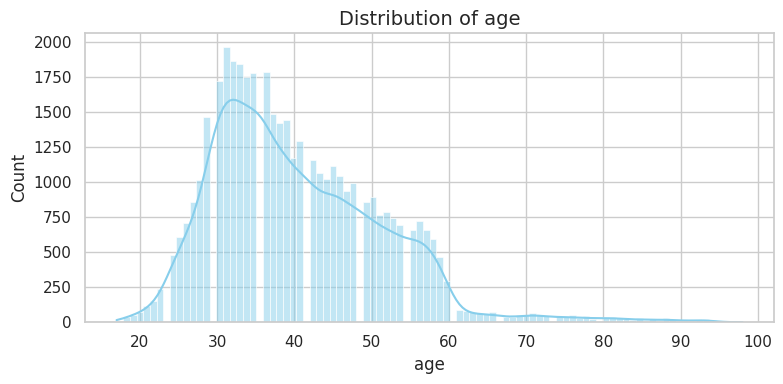

Skewness: 1.01   →    RIGHT-SKEWED — long tail on the right



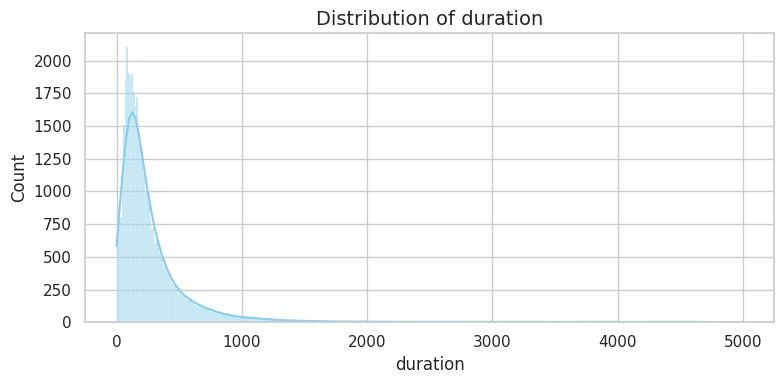

Skewness: 5.57   →    RIGHT-SKEWED — long tail on the right



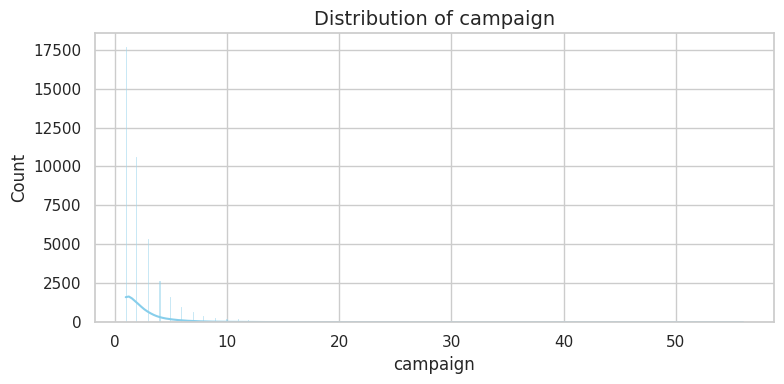

Skewness: 5.57   →    RIGHT-SKEWED — long tail on the right



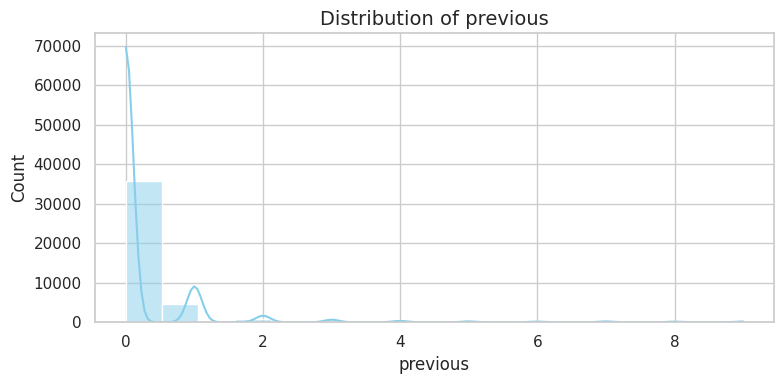

Skewness: 5.81   →    RIGHT-SKEWED — long tail on the right



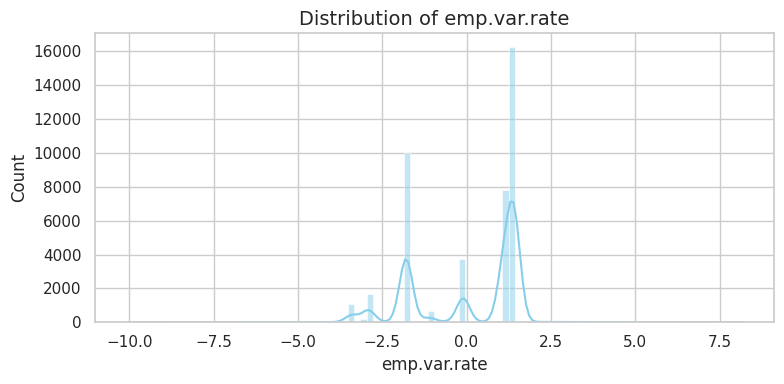

Skewness: -0.67   →    ROUGHLY SYMMETRIC



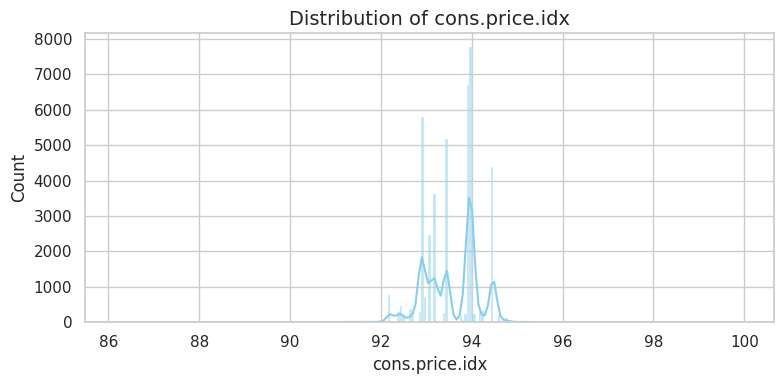

Skewness: -0.66   →    ROUGHLY SYMMETRIC



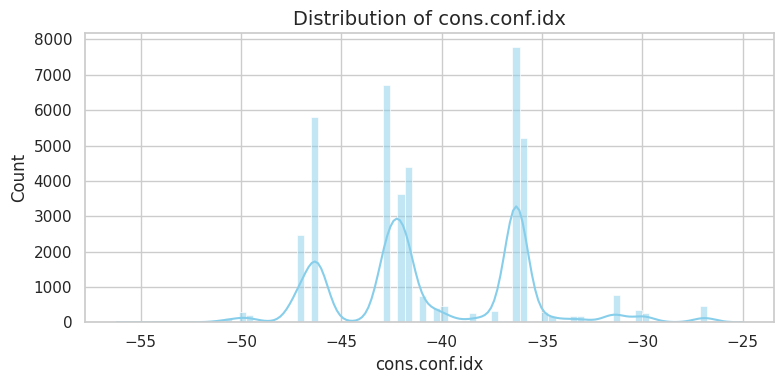

Skewness: 0.29   →    ROUGHLY SYMMETRIC



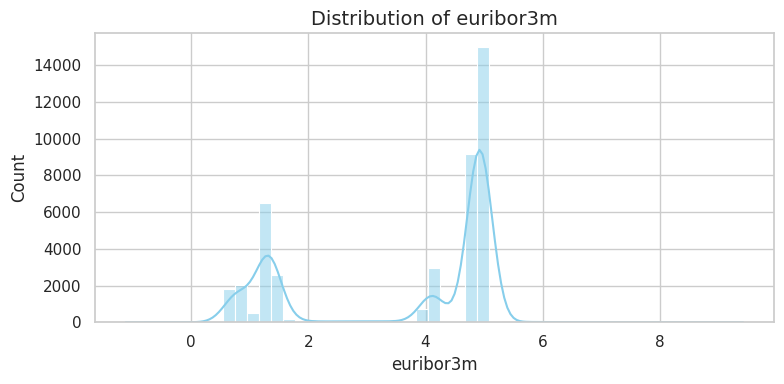

Skewness: -0.70   →    ROUGHLY SYMMETRIC



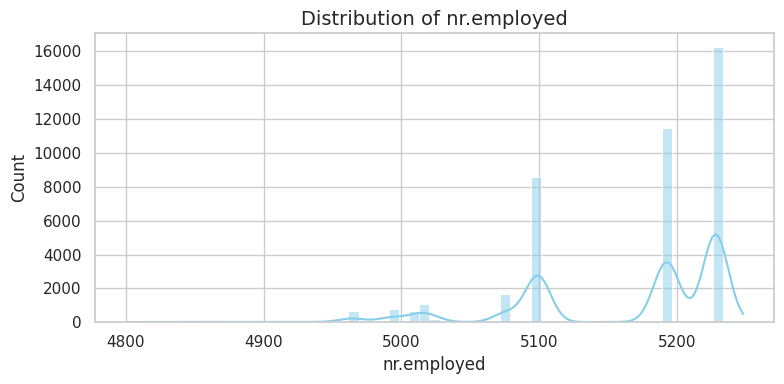

Skewness: -1.22   →    LEFT-SKEWED — long tail on the left



In [ ]:
#  — Numeric Distributions: What shapes do we see?
# Histogram + KDE shows the distribution shape of each column

num_cols = ['age', 'duration', 'campaign', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed']

for col in num_cols:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(df2[col].dropna(), kde=True, ax=ax, color='skyblue')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    plt.tight_layout()
    plt.show()

    # 1 line interpretation per column
    skew = df2[col].skew()
    print(f"Skewness: {skew:.2f}", end="   →   ")
    if skew > 1:
        print(f" RIGHT-SKEWED — long tail on the right")
    elif skew < -1:
        print(f" LEFT-SKEWED — long tail on the left")
    else:
        print(f" ROUGHLY SYMMETRIC")
    print()

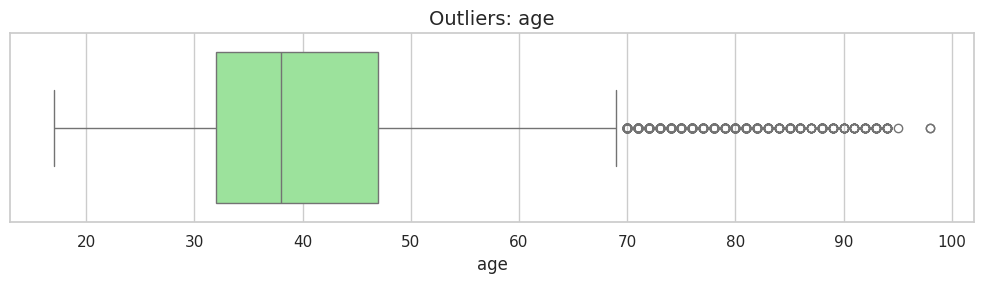

 782 outliers (1.9%) — Values < 9.50 or > 69.50
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



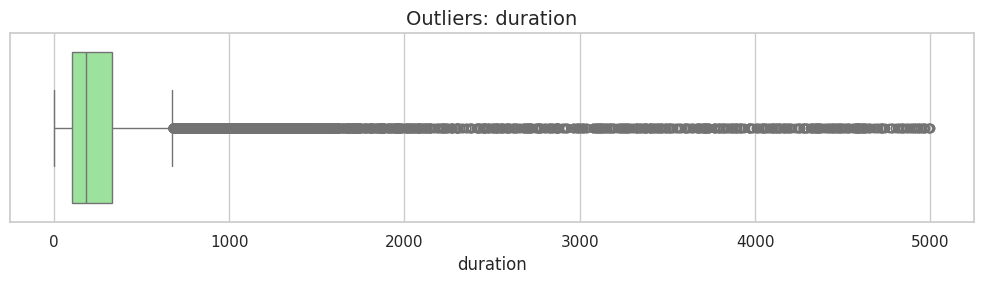

 3481 outliers (8.3%) — Values < -239.50 or > 676.50
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



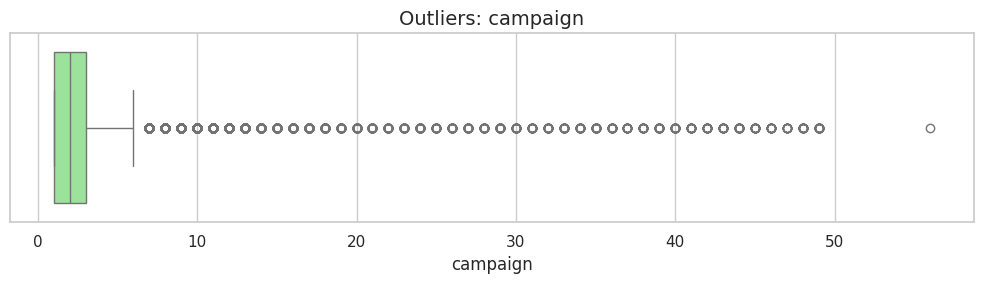

 3228 outliers (7.7%) — Values < -2.00 or > 6.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



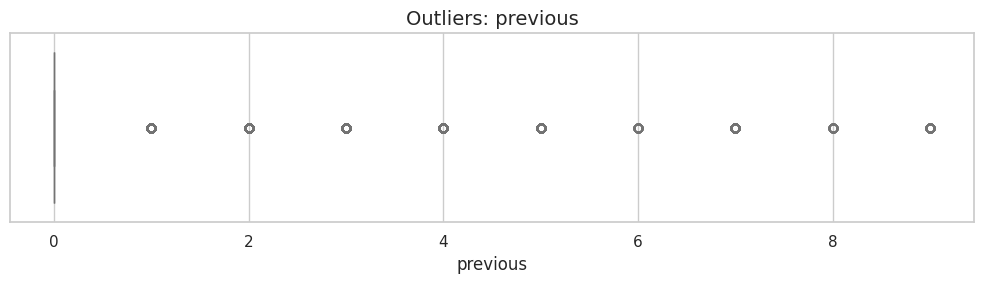

 6478 outliers (15.4%) — Values < 0.00 or > 0.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



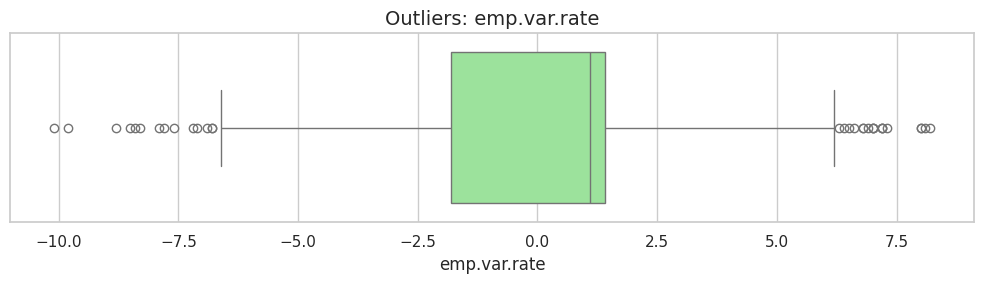

 32 outliers (0.1%) — Values < -6.60 or > 6.20
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



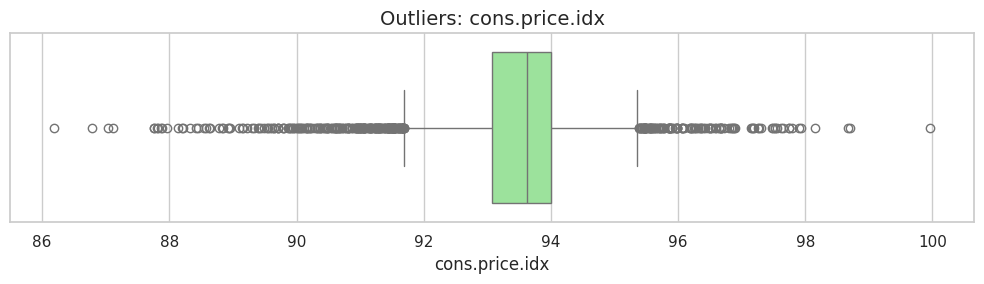

 341 outliers (0.8%) — Values < 91.70 or > 95.37
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



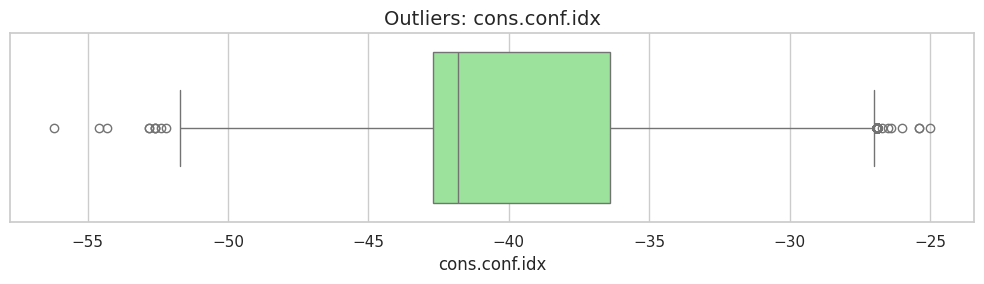

 464 outliers (1.1%) — Values < -52.15 or > -26.95
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



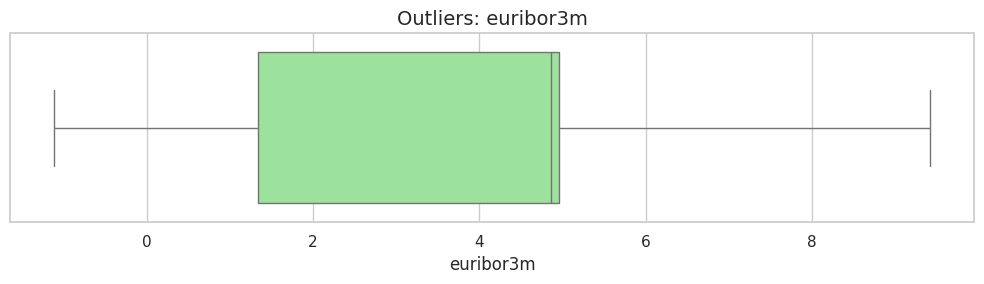

 No outliers detected via IQR method



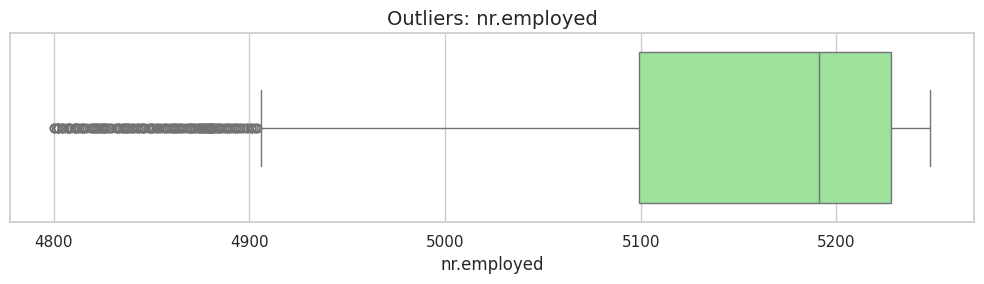

 231 outliers (0.5%) — Values < 4905.50 or > 5421.50
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



In [ ]:
#  — Outliers: Do numeric columns have extreme values?
# Boxplot shows spread + outliers using IQR method
# Box = IQR (25%–75%) | Whiskers = 1.5×IQR | Dots = Outliers
num_cols = ['age', 'duration', 'campaign', 'previous',
        'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
           'euribor3m', 'nr.employed']

for col in num_cols:
    fig, ax = plt.subplots(figsize=(10, 3))
    sns.boxplot(x=df2[col], ax=ax, color='lightgreen')
    ax.set_title(f'Outliers: {col}')
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()

    # IQR outlier count per column
    Q1  = df2[col].quantile(0.25)
    Q3  = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower   = Q1 - 1.5 * IQR
    upper   = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    pct = len(outliers) / len(df2) * 100

    if len(outliers) > 0:
        print(f" {len(outliers)} outliers ({pct:.1f}%) — Values < {lower:.2f} or > {upper:.2f}")
        print(f"      -> ACTION (If Error): Remove rows")
        print(f"      -> ACTION (If Valid): Cap values at thresholds")
    else:
        print(f" No outliers detected via IQR method")
    print()

# **Outlier**
duration (Max 4999s) → (ACTION) CAP: These values are highly anomalous and unreasonable. Leaving them would severely skew the predictive model and hinder the training process.

campaign (Max 56) → (ACTION) CAP at 10: Unrealistic and highly exaggerated numbers, most likely caused by a technical error in the CRM system.

age (Max 98) → KEEP: Valid demographic data representing a real and highly targeted retiree segment.

previous (Max 9) → KEEP: The range is small and limited, and all values within it are completely logical.

Economic Indicators → KEEP: These reflect real macroeconomic market data. Modifying them would falsify the economic reality.

In [ ]:
# Model Accuracy BEFORE EDA Cleaning
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, r2_score

# Columns removed from both models:
# duration → data leakage (known only after call)
# pdays    → sentinel value 999 (not real numeric)
# campaign → outlier-heavy (max 56)
drop_cols = ['duration', 'pdays', 'campaign']

df_before = df.copy()
df_before['y'] = df_before['y'].map({'yes': 1, 'no': 0})
df_before = df_before.drop(columns=drop_cols)
df_before = pd.get_dummies(df_before, drop_first=True)
df_before = df_before.dropna()

X = df_before.drop(columns=['y'])
y = df_before['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y)

scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

model_before   = LogisticRegression(max_iter=1000,
                                    random_state=RANDOM_STATE)
model_before.fit(X_train_scaled, y_train)

y_pred          = model_before.predict(X_test_scaled)
accuracy_before = accuracy_score(y_test, y_pred)
score_before    = r2_score(y_test, y_pred)

print("=" * 55)
print("  BEFORE Cleaning")
print("=" * 55)
print(f"  Accuracy : {accuracy_before * 100:.2f}%")
print(f"  R-Square : {score_before:.4f}")

  BEFORE Cleaning
  Accuracy : 89.54%
  R-Square : 0.0001
